# Project: Compare CNN and ViT (no position enc) against each other!

This notebook will be the primary vehicle for creating, training, evaluating the models.

# 0. Initial Library imports

From the project root, run `bash setup_venv.sh`, then `source .venv/bin/activate`
and `jupyter lab src/project.ipynb`. Select the **Python (coms474)** kernel.

In [1]:
# Standard library: paths, downloads, reproducibility, and timing
import json
import random
import time
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

# Data analysis and visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

# PyTorch models, optimization, image transforms, and data loading
import torch
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, models, transforms

/home/tyler/coms474/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Dataset download & Setup

In [2]:
# Download TinyImageNet once; reuse the extracted data or cached ZIP on reruns.
# Resolve src/data whether Jupyter starts in the project root or in src.
PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src" / "project.ipynb").is_file()
)
DATA_DIR = PROJECT_ROOT / "src" / "data"
DATASET_DIR = DATA_DIR / "tiny-imagenet-200"
ARCHIVE_PATH = DATA_DIR / "tiny-imagenet-200.zip"
DATASET_URL = "https://cs231n.stanford.edu/tiny-imagenet-200.zip"
DATA_DIR.mkdir(parents=True, exist_ok=True)


def dataset_is_ready():
    # Check image counts as well as directories to detect interrupted extraction.
    required = [DATASET_DIR / "wnids.txt", DATASET_DIR / "words.txt",
                DATASET_DIR / "val" / "val_annotations.txt"]
    if not all(path.is_file() for path in required):
        return False
    wnids = required[0].read_text().splitlines()
    return (
        len(set(wnids)) == 200
        and all(len(list((DATASET_DIR / "train" / wnid / "images").glob("*.JPEG"))) == 500
                for wnid in wnids)
        and len(list((DATASET_DIR / "val" / "images").glob("*.JPEG"))) == 10_000
    )


if not dataset_is_ready():
    if not ARCHIVE_PATH.is_file():
        # Rename only after a successful download so interrupted files aren't reused.
        partial_path = ARCHIVE_PATH.with_suffix(".zip.part")
        print(f"Downloading {DATASET_URL} ...")
        urlretrieve(DATASET_URL, partial_path)
        partial_path.replace(ARCHIVE_PATH)

    print(f"Extracting {ARCHIVE_PATH.name} ...")
    with ZipFile(ARCHIVE_PATH) as archive:
        # Keep every archive member inside the data directory.
        for name in archive.namelist():
            if not (DATA_DIR / name).resolve().is_relative_to(DATA_DIR.resolve()):
                raise ValueError(f"Unsafe archive path: {name}")
        archive.extractall(DATA_DIR)

    if not dataset_is_ready():
        raise RuntimeError("TinyImageNet extraction is incomplete. Check the cached ZIP and rerun.")

print(f"TinyImageNet is ready at {DATASET_DIR}")


TinyImageNet is ready at /home/tyler/coms474/src/data/tiny-imagenet-200


In [3]:
# Shared data pipeline for the CNN and ViT: 100,000 train / 10,000 validation.
SEED = 67
BATCH_SIZE = 128
NUM_WORKERS = 0 # default
IMAGE_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Fixed ImageNet normalization.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    transforms.RandomCrop(IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


train_dataset = datasets.ImageFolder(DATASET_DIR / "train", transform=train_transform)
class_to_idx = train_dataset.class_to_idx
classes = train_dataset.classes
NUM_CLASSES = len(classes)


class TinyImageNetValidation(Dataset):
    """Read the official flat validation layout without moving or copying images."""

    def __init__(self, root, class_to_idx, transform):
        self.transform = transform
        self.class_to_idx = dict(class_to_idx)
        self.classes = sorted(class_to_idx, key=class_to_idx.get)
        self.samples = []
        for line in (root / "val_annotations.txt").read_text().splitlines():
            filename, wnid, *_ = line.split()
            self.samples.append((root / "images" / filename, class_to_idx[wnid]))
        self.targets = [target for _, target in self.samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, target = self.samples[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
        return self.transform(image), target


val_dataset = TinyImageNetValidation(DATASET_DIR / "val", class_to_idx, eval_transform)
words = dict(line.split("\t", 1) for line in (DATASET_DIR / "words.txt").read_text().splitlines())
class_names = [words[wnid] for wnid in classes]


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_train_loader(seed=SEED):
    return DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(seed),
    )


train_loader = make_train_loader()
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
)

print(f"Device: {DEVICE}; classes: {NUM_CLASSES}; batch size: {BATCH_SIZE}")
print(f"Training images: {len(train_dataset):,}; validation images: {len(val_dataset):,}")
print(f"Model input shape: (batch, 3, {IMAGE_SIZE}, {IMAGE_SIZE})")


Device: cuda; classes: 200; batch size: 128
Training images: 100,000; validation images: 10,000
Model input shape: (batch, 3, 64, 64)


# 2. Convolutional Neural Network

AlexNet adapted to TinyImageNet's 64×64 images: five convolution layers and
three linear layers, with a smaller stem and classifier than the ImageNet model.
All layers are explicitly defined with `nn.Sequential`; training starts from scratch.

The training cell runs **3 batch sizes × 3 learning rates**, then **3 bootstrap
retrainings** of the winning configuration for bias²/variance estimation. Each run
uses 10 epochs by default. Adjust the settings below before running.

We reserve a stratified 10% of the training images for tuning. The official labeled
validation set is held out for final evaluation and is never used to select the
configuration or epoch. Keep this same split for the later ViT comparison.

Set `SKIP_TRAINING_IF_EXISTS = True` to reuse completed matching checkpoints.
Changing the architecture, data split, preprocessing, or training settings creates
new checkpoints. Set it to `False` to retrain. Artifacts go to `src/output/cnn/`.

Bias² and variance are empirical bootstrap estimates on **class probabilities**
with summed squared error (multiclass Brier score), not a decomposition of top-1
classification error. Three repeats give a rough estimate; increase the repeat
count for greater stability. The estimates include resampling and training
randomness, and cannot identify the population's irreducible label noise.

References: [PyTorch's AlexNet layers](https://docs.pytorch.org/vision/stable/_modules/torchvision/models/alexnet.html),
[checkpoint loading](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html),
and [bias/variance from repeated training sets](https://scikit-learn.org/stable/auto_examples/ensemble/plot_bias_variance.html).


In [4]:
import hashlib
import multiprocessing as mp
from itertools import product
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

CNN_OUTPUT_DIR = PROJECT_ROOT / "src" / "output" / "cnn"
CNN_CHECKPOINT_DIR = CNN_OUTPUT_DIR / "checkpoints"
CNN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Experiment controls. Cached runs retain their original measured training times.
SKIP_TRAINING_IF_EXISTS = True
CNN_BATCH_SIZES = [64, 128, 256]
CNN_LEARNING_RATES = [1e-4, 3e-4, 1e-3]
CNN_EPOCHS = 10
CNN_WEIGHT_DECAY = 1e-4
CNN_TUNING_FRACTION = 0.10
CNN_BOOTSTRAP_REPEATS = 3  # Additional fits of the selected configuration.
# Fork keeps notebook-defined datasets/workers usable on Linux. Workers load CPU tensors only.
CNN_NUM_WORKERS = 4 if "fork" in mp.get_all_start_methods() else 0
CNN_USE_AMP = True  # Mixed precision on CUDA; float32 on CPU.
CNN_ARCHITECTURE = {"name": "alexnet64_v1", "num_classes": NUM_CLASSES,
                    "hidden_features": 1024, "dropout": 0.5}


def build_cnn(architecture=None):
    config = CNN_ARCHITECTURE if architecture is None else architecture
    if config["name"] != "alexnet64_v1":
        raise ValueError(f"Unknown CNN architecture: {config['name']}")
    hidden = config["hidden_features"]
    # AlexNet channel widths and five-convolution / three-linear structure.
    # A 5x5, stride-2 stem preserves detail in 64x64 images; the compact head
    # avoids upsampling the feature map to the original model's 6x6 grid.
    return nn.Sequential(
        nn.Conv2d(3, 64, kernel_size=5, stride=2, padding=2),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
        nn.Conv2d(64, 192, kernel_size=5, padding=2),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
        nn.Conv2d(192, 384, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(384, 256, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(256, 256, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
        nn.AdaptiveAvgPool2d((2, 2)),
        nn.Flatten(),
        nn.Dropout(config["dropout"]),
        nn.Linear(256 * 2 * 2, hidden),
        nn.ReLU(inplace=True),
        nn.Dropout(config["dropout"]),
        nn.Linear(hidden, hidden),
        nn.ReLU(inplace=True),
        nn.Linear(hidden, config["num_classes"]),
    )


def save_cnn_checkpoint(checkpoint, path):
    # Atomic replacement leaves the previous complete file intact on interruption.
    temporary = path.with_suffix(".pt.tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(path)


def load_cnn_checkpoint(path, device=DEVICE):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if checkpoint["class_to_idx"] != class_to_idx:
        raise ValueError("Checkpoint class mapping differs from this dataset.")
    model = build_cnn(checkpoint["config"]["architecture"])
    model.load_state_dict(checkpoint["model_state_dict"])
    return model.to(device).eval(), checkpoint


CNN_MODEL_PATH = CNN_OUTPUT_DIR / "alexnet_best.pt"
cnn_model = build_cnn().to(DEVICE)
print(cnn_model)
print(f"Parameters: {sum(p.numel() for p in cnn_model.parameters()):,}; device: {DEVICE}")


Sequential(
  (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU(inplace=True)
  (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU(inplace=True)
  (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (13): AdaptiveAvgPool2d(output_size=(2, 2))
  (14): Flatten(start_dim=1, end_dim=-1)
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=1024, out_features=1024, bias=True)
  (17): ReLU(inplace=True)
  (18): Dropout(p=0.5, 

In [5]:
if CNN_EPOCHS < 1 or CNN_BOOTSTRAP_REPEATS < 2:
    raise ValueError("Use at least one epoch and two bootstrap repeats.")
if any(value < 1 for value in CNN_BATCH_SIZES) or any(value <= 0 for value in CNN_LEARNING_RATES):
    raise ValueError("Batch sizes and learning rates must be positive.")

# A fixed, stratified tuning split, independent of the official validation set.
cnn_train_indices, cnn_tuning_indices = train_test_split(
    np.arange(len(train_dataset)), test_size=CNN_TUNING_FRACTION,
    stratify=train_dataset.targets, random_state=SEED,
)
cnn_clean_train_dataset = datasets.ImageFolder(DATASET_DIR / "train", transform=eval_transform)
assert cnn_clean_train_dataset.samples == train_dataset.samples
cnn_tuning_dataset = Subset(cnn_clean_train_dataset, cnn_tuning_indices.tolist())
np.savez(CNN_OUTPUT_DIR / "data_split.npz", train_indices=cnn_train_indices,
         tuning_indices=cnn_tuning_indices, seed=SEED)


def cnn_loader(dataset, batch_size, shuffle=False, seed=SEED):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=CNN_NUM_WORKERS,
        multiprocessing_context="fork" if CNN_NUM_WORKERS else None,
        persistent_workers=CNN_NUM_WORKERS > 0,
        pin_memory=DEVICE.type == "cuda", worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(seed),
    )


def synchronize_cnn_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def cnn_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=training and cnn_amp_enabled):
                logits = model(images)
                loss = F.cross_entropy(logits, targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; lower the learning rate or disable AMP.")
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            size = targets.size(0)
            loss_sum += loss.detach().item() * size
            correct += (logits.detach().argmax(1) == targets).sum().item()
            count += size
    return {"loss": loss_sum / count, "accuracy": correct / count}


cnn_amp_enabled = CNN_USE_AMP and DEVICE.type == "cuda"
cnn_protocol = {
    "architecture": dict(CNN_ARCHITECTURE), "epochs": CNN_EPOCHS,
    "optimizer": "AdamW", "weight_decay": CNN_WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR", "seed": SEED,
    "class_to_idx": dict(class_to_idx), "mean": list(MEAN), "std": list(STD),
    "image_size": IMAGE_SIZE, "amp_requested": CNN_USE_AMP, "num_workers": CNN_NUM_WORKERS,
    "train_transform": repr(train_transform), "eval_transform": repr(eval_transform),
    "tuning_indices_sha256": hashlib.sha256(cnn_tuning_indices.tobytes()).hexdigest(),
    "training_samples": len(train_dataset), "training_root": str(DATASET_DIR.resolve()),
}


def fit_or_load_cnn(batch_size, learning_rate, run_seed, indices, kind):
    config = {**cnn_protocol, "batch_size": int(batch_size),
              "learning_rate": float(learning_rate), "run_seed": int(run_seed),
              "kind": kind,
              "sample_indices_sha256": hashlib.sha256(indices.tobytes()).hexdigest()}
    fingerprint = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
    run_id = f"{kind}_bs{batch_size}_lr{learning_rate:g}_seed{run_seed}_{fingerprint}"
    checkpoint_path = CNN_CHECKPOINT_DIR / f"{run_id}.pt"
    checkpoint = None
    if SKIP_TRAINING_IF_EXISTS and checkpoint_path.is_file():
        candidate = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if candidate.get("complete") and candidate.get("config") == config:
            checkpoint = candidate
            print(f"Reusing {run_id}")

    cached = checkpoint is not None
    if not cached:
        random.seed(run_seed)
        np.random.seed(run_seed)
        torch.manual_seed(run_seed)
        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(run_seed)
        model = build_cnn().to(DEVICE)
        optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=CNN_WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CNN_EPOCHS)
        scaler = torch.amp.GradScaler("cuda", enabled=cnn_amp_enabled)
        loader = cnn_loader(Subset(train_dataset, indices.tolist()), batch_size, True, run_seed)
        tuning_loader = cnn_loader(cnn_tuning_dataset, batch_size, seed=run_seed)
        history, best_score = [], (-1.0, -float("inf"))
        best_state, best_epoch = None, 0
        progress = tqdm(range(1, CNN_EPOCHS + 1), desc=run_id)
        for epoch in progress:
            synchronize_cnn_device()
            start = time.perf_counter()
            train_metrics = cnn_epoch(model, loader, optimizer, scaler)
            synchronize_cnn_device()
            train_seconds = time.perf_counter() - start
            start = time.perf_counter()
            tuning_metrics = cnn_epoch(model, tuning_loader)
            synchronize_cnn_device()
            tuning_seconds = time.perf_counter() - start
            history.append({
                "epoch": epoch, "learning_rate": optimizer.param_groups[0]["lr"],
                "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
                "tuning_loss": tuning_metrics["loss"], "tuning_accuracy": tuning_metrics["accuracy"],
                "train_seconds": train_seconds, "tuning_seconds": tuning_seconds,
            })
            score = (tuning_metrics["accuracy"], -tuning_metrics["loss"])
            if score > best_score:
                best_score, best_epoch = score, epoch
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            checkpoint = {
                "model_state_dict": best_state, "config": config, "class_to_idx": dict(class_to_idx),
                "class_names": list(class_names), "history": list(history), "best_epoch": best_epoch,
                "best_tuning_accuracy": best_score[0], "best_tuning_loss": -best_score[1],
                "training_seconds": sum(row["train_seconds"] for row in history),
                "tuning_seconds": sum(row["tuning_seconds"] for row in history),
                "device_used": str(DEVICE), "amp_used": cnn_amp_enabled,
                "complete": epoch == CNN_EPOCHS,
            }
            save_cnn_checkpoint(checkpoint, checkpoint_path)
            scheduler.step()
            progress.set_postfix(train_acc=f"{train_metrics['accuracy']:.3f}",
                                 tuning_acc=f"{tuning_metrics['accuracy']:.3f}")
        del model, optimizer, scheduler, scaler, loader, tuning_loader

    pd.DataFrame(checkpoint["history"]).to_csv(CNN_OUTPUT_DIR / f"{run_id}_history.csv", index=False)
    return {"run_id": run_id, "batch_size": int(batch_size), "learning_rate": float(learning_rate),
            "seed": int(run_seed), "checkpoint": str(checkpoint_path), "loaded_from_cache": cached,
            "best_epoch": checkpoint["best_epoch"],
            "best_tuning_accuracy": checkpoint["best_tuning_accuracy"],
            "best_tuning_loss": checkpoint["best_tuning_loss"],
            "training_seconds": checkpoint["training_seconds"], "tuning_seconds": checkpoint["tuning_seconds"]}


cnn_grid_runs = []
for batch_size, learning_rate in product(CNN_BATCH_SIZES, CNN_LEARNING_RATES):
    cnn_grid_runs.append(fit_or_load_cnn(batch_size, learning_rate, SEED, cnn_train_indices, "grid"))
    pd.DataFrame(cnn_grid_runs).to_csv(CNN_OUTPUT_DIR / "training_runs.csv", index=False)

# Select exclusively by tuning performance, before evaluating the held-out images.
cnn_best_run = sorted(cnn_grid_runs, key=lambda run: (-run["best_tuning_accuracy"], run["best_tuning_loss"]))[0]
cnn_best_checkpoint_path = Path(cnn_best_run["checkpoint"])
cnn_model, cnn_best_checkpoint = load_cnn_checkpoint(cnn_best_checkpoint_path)
save_cnn_checkpoint(cnn_best_checkpoint, CNN_OUTPUT_DIR / "alexnet_best.pt")
print(f"Selected batch size {cnn_best_run['batch_size']}, learning rate {cnn_best_run['learning_rate']:g}")

# Repeated training datasets, not different hyperparameters, define this estimate.
cnn_bootstrap_runs = []
for repeat in range(CNN_BOOTSTRAP_REPEATS):
    bootstrap_seed = SEED + 1000 + repeat
    bootstrap_indices = np.random.default_rng(bootstrap_seed).choice(
        cnn_train_indices, size=len(cnn_train_indices), replace=True,
    )
    cnn_bootstrap_runs.append(fit_or_load_cnn(
        cnn_best_run["batch_size"], cnn_best_run["learning_rate"], bootstrap_seed,
        bootstrap_indices, "bootstrap",
    ))
    pd.DataFrame(cnn_bootstrap_runs).to_csv(CNN_OUTPUT_DIR / "bootstrap_runs.csv", index=False)

cnn_training_seconds = sum(run["training_seconds"] for run in cnn_grid_runs + cnn_bootstrap_runs)
cnn_training_summary = {
    "best_run": cnn_best_run, "grid_runs": cnn_grid_runs, "bootstrap_runs": cnn_bootstrap_runs,
    "total_training_seconds": cnn_training_seconds,
    "total_tuning_seconds": sum(run["tuning_seconds"] for run in cnn_grid_runs + cnn_bootstrap_runs),
    "train_images": len(cnn_train_indices), "tuning_images": len(cnn_tuning_indices),
    "held_out_images": len(val_dataset), "protocol": cnn_protocol,
    "timing_note": "Training includes loading, augmentation, transfers, forward/backward and updates; "
                   "tuning is timed separately. CUDA is synchronized. Checkpoint I/O is excluded. "
                   "Cached runs retain their original times.",
}
(CNN_OUTPUT_DIR / "training_summary.json").write_text(json.dumps(cnn_training_summary, indent=2))
print(f"Total recorded training time (grid + bootstrap): {cnn_training_seconds / 60:.2f} min")
display(pd.DataFrame(cnn_grid_runs)[["batch_size", "learning_rate", "best_epoch",
                                      "best_tuning_accuracy", "training_seconds", "loaded_from_cache"]])


grid_bs64_lr0.0001_seed67_7c848101074b:   0%|          | 0/10 [00:00<?, ?it/s]

grid_bs64_lr0.0001_seed67_7c848101074b:   0%|          | 0/10 [00:16<?, ?it/s, train_acc=0.016, tuning_acc=0.032]

grid_bs64_lr0.0001_seed67_7c848101074b:  10%|█         | 1/10 [00:16<02:24, 16.06s/it, train_acc=0.016, tuning_acc=0.032]

grid_bs64_lr0.0001_seed67_7c848101074b:  10%|█         | 1/10 [00:29<02:24, 16.06s/it, train_acc=0.046, tuning_acc=0.076]

grid_bs64_lr0.0001_seed67_7c848101074b:  20%|██        | 2/10 [00:29<01:57, 14.69s/it, train_acc=0.046, tuning_acc=0.076]

...

bootstrap_bs64_lr0.0003_seed1069_f2689f5b31df:  90%|█████████ | 9/10 [02:21<00:14, 14.07s/it, train_acc=0.250, tuning_acc=0.221]

bootstrap_bs64_lr0.0003_seed1069_f2689f5b31df: 100%|██████████| 10/10 [02:21<00:00, 14.15s/it, train_acc=0.250, tuning_acc=0.221]

bootstrap_bs64_lr0.0003_seed1069_f2689f5b31df: 100%|██████████| 10/10 [02:21<00:00, 14.18s/it, train_acc=0.250, tuning_acc=0.221]

Total recorded training time (grid + bootstrap): 23.65 min


,batch_size,learning_rate,best_epoch,best_tuning_accuracy,training_seconds,loaded_from_cache
0,64,0.0001,10,0.2158,131.595057,False
1,64,0.0003,10,0.2222,128.267729,False
2,64,0.0010,9,0.0050,132.208420,False
3,128,0.0001,10,0.1806,109.261814,False
4,128,0.0003,10,0.2179,110.578347,False
5,128,0.0010,10,0.1274,105.020164,False
6,256,0.0001,10,0.1406,98.570030,False
7,256,0.0003,10,0.2043,99.297535,False
8,256,0.0010,10,0.1456,98.438400,False


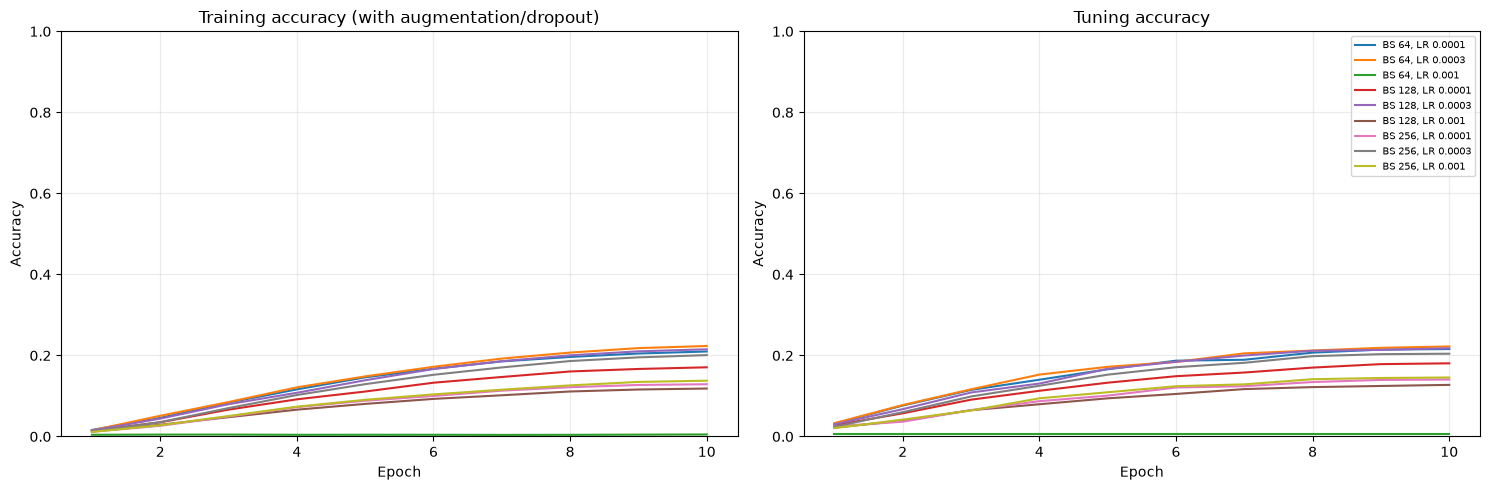

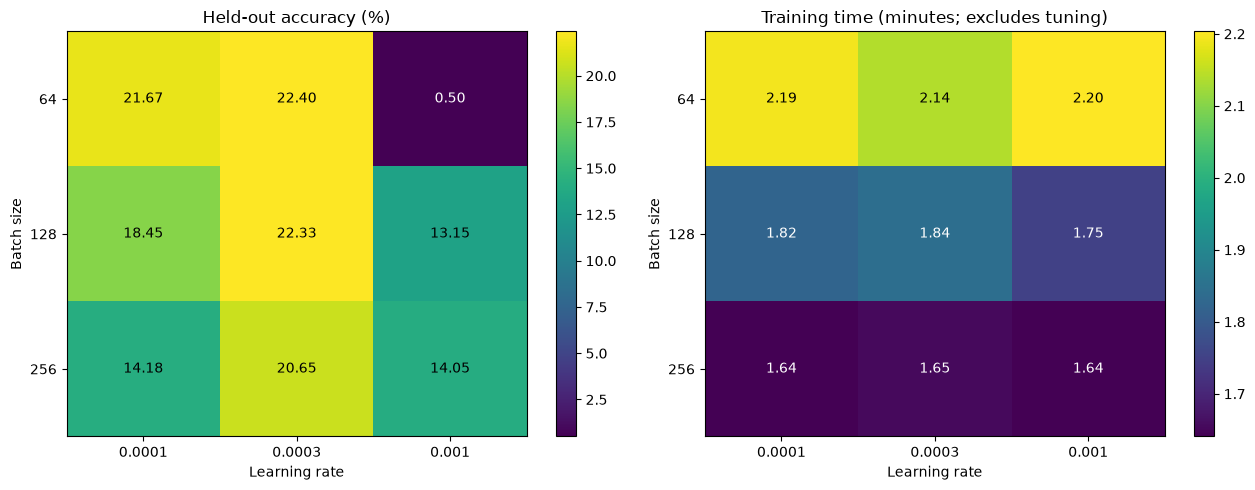

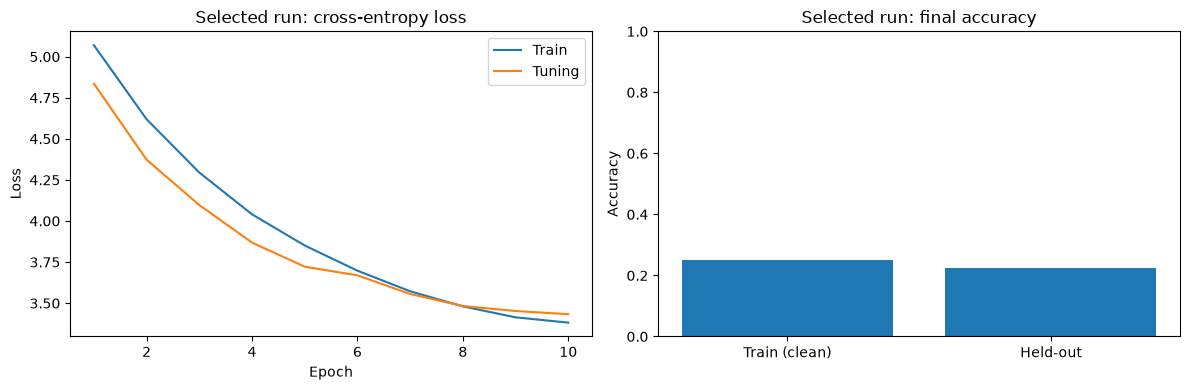

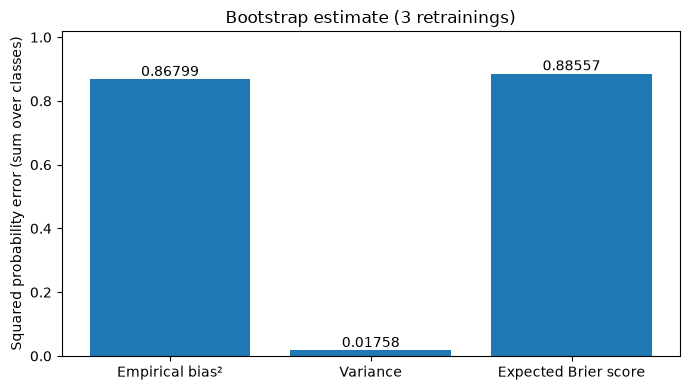

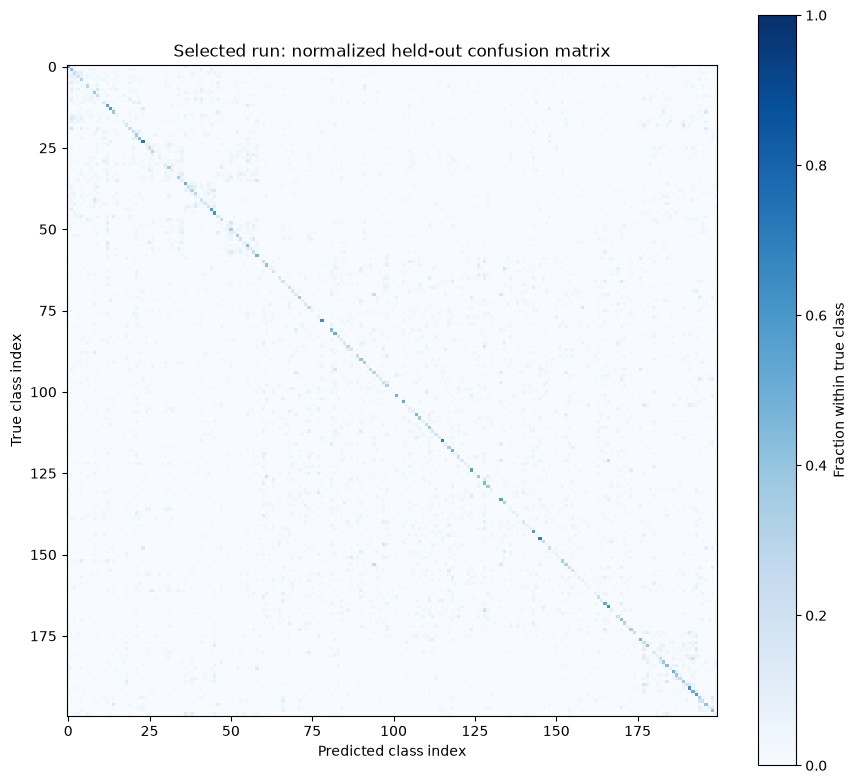

{
  "model": "AlexNet adapted for 64x64",
  "best_run_id": "grid_bs64_lr0.0003_seed67_529704f80409",
  "parameter_count": 4755464,
  "train_accuracy": 0.2494111111111111,
  "held_out_accuracy": 0.224,
  "accuracy_gap_train_minus_held_out": 0.025411111111111107,
  "selected_model_training_seconds": 128.26772853109287,
  "grid_training_seconds": 1013.2374964674818,
  "bootstrap_training_seconds": 405.6244921008474,
  "total_training_seconds": 1418.8619885683293,
  "empirical_bootstrap_bias_squared": 0.8679918519349853,
  "empirical_bootstrap_variance": 0.017577756469464335,
  "bootstrap_expected_brier_score": 0.8855696084044498,
  "bootstrap_repeats": 3,
  "bias_variance_note": "Summed squared probability error against observed one-hot labels. Finite bootstrap estimate, not a decomposition of top-1 error; irreducible label noise is not separately identifiable."
}


In [6]:
@torch.inference_mode()
def cnn_predict(model, loader):
    model.eval()
    probabilities, labels = [], []
    for images, targets in loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        probabilities.append(logits.softmax(dim=1).cpu().numpy())
        labels.append(targets.numpy())
    return np.concatenate(probabilities), np.concatenate(labels)


cnn_evaluation_loader = cnn_loader(val_dataset, BATCH_SIZE)
cnn_results, cnn_best_probabilities, cnn_targets = [], None, None
for run in cnn_grid_runs:
    evaluated_model, _ = load_cnn_checkpoint(Path(run["checkpoint"]))
    probabilities, targets = cnn_predict(evaluated_model, cnn_evaluation_loader)
    predictions = probabilities.argmax(axis=1)
    result = {**run, "held_out_accuracy": float(accuracy_score(targets, predictions))}
    cnn_results.append(result)
    if run["run_id"] == cnn_best_run["run_id"]:
        cnn_best_probabilities, cnn_targets = probabilities, targets
    del evaluated_model

cnn_results_df = pd.DataFrame(cnn_results)
cnn_results_df.to_csv(CNN_OUTPUT_DIR / "evaluation_runs.csv", index=False)
cnn_predictions = cnn_best_probabilities.argmax(axis=1)
cnn_train_evaluation_loader = cnn_loader(
    Subset(cnn_clean_train_dataset, cnn_train_indices.tolist()), BATCH_SIZE,
)
cnn_train_metrics = cnn_epoch(cnn_model, cnn_train_evaluation_loader)
cnn_held_out_accuracy = float(accuracy_score(cnn_targets, cnn_predictions))

report = classification_report(cnn_targets, cnn_predictions, labels=list(range(NUM_CLASSES)),
                               target_names=class_names, output_dict=True, zero_division=0)
(CNN_OUTPUT_DIR / "classification_report.json").write_text(json.dumps(report, indent=2))
cnn_confusion = confusion_matrix(cnn_targets, cnn_predictions, labels=list(range(NUM_CLASSES)))
np.save(CNN_OUTPUT_DIR / "confusion_matrix.npy", cnn_confusion)
np.savez_compressed(CNN_OUTPUT_DIR / "best_predictions.npz", probabilities=cnn_best_probabilities,
                    targets=cnn_targets, predictions=cnn_predictions)

# Bootstrap probability decomposition, summing across classes (Brier convention):
# bias² = mean_x ||mean_m p_m(x) - one_hot(y)||²
# variance = mean_x mean_m ||p_m(x) - mean_m p_m(x)||²
# mean squared error = bias² + variance for this finite set of fitted models.
cnn_bootstrap_probabilities = []
for run in cnn_bootstrap_runs:
    bootstrap_model, _ = load_cnn_checkpoint(Path(run["checkpoint"]))
    probabilities, targets = cnn_predict(bootstrap_model, cnn_evaluation_loader)
    if not np.array_equal(targets, cnn_targets):
        raise RuntimeError("Bootstrap predictions and labels are not aligned.")
    cnn_bootstrap_probabilities.append(probabilities)
    del bootstrap_model
cnn_bootstrap_probabilities = np.stack(cnn_bootstrap_probabilities).astype(np.float64)
cnn_mean_probability = cnn_bootstrap_probabilities.mean(axis=0)
cnn_one_hot = np.eye(NUM_CLASSES, dtype=np.float64)[cnn_targets]
cnn_bias_squared = float(np.square(cnn_mean_probability - cnn_one_hot).sum(axis=1).mean())
cnn_variance = float(np.square(cnn_bootstrap_probabilities - cnn_mean_probability).sum(axis=2).mean())
cnn_expected_squared_error = float(np.square(cnn_bootstrap_probabilities - cnn_one_hot).sum(axis=2).mean())
assert np.isclose(cnn_expected_squared_error, cnn_bias_squared + cnn_variance)
np.savez_compressed(CNN_OUTPUT_DIR / "bootstrap_predictions.npz",
                    probabilities=cnn_bootstrap_probabilities.astype(np.float32), targets=cnn_targets)

cnn_metrics = {
    "model": "AlexNet adapted for 64x64", "best_run_id": cnn_best_run["run_id"],
    "parameter_count": sum(parameter.numel() for parameter in cnn_model.parameters()),
    "train_accuracy": cnn_train_metrics["accuracy"], "held_out_accuracy": cnn_held_out_accuracy,
    "accuracy_gap_train_minus_held_out": cnn_train_metrics["accuracy"] - cnn_held_out_accuracy,
    "selected_model_training_seconds": cnn_best_run["training_seconds"],
    "grid_training_seconds": sum(run["training_seconds"] for run in cnn_grid_runs),
    "bootstrap_training_seconds": sum(run["training_seconds"] for run in cnn_bootstrap_runs),
    "total_training_seconds": cnn_training_seconds,
    "empirical_bootstrap_bias_squared": cnn_bias_squared, "empirical_bootstrap_variance": cnn_variance,
    "bootstrap_expected_brier_score": cnn_expected_squared_error,
    "bootstrap_repeats": len(cnn_bootstrap_runs),
    "bias_variance_note": "Summed squared probability error against observed one-hot labels. "
                          "Finite bootstrap estimate, not a decomposition of top-1 error; "
                          "irreducible label noise is not separately identifiable.",
}
(CNN_OUTPUT_DIR / "metrics.json").write_text(json.dumps(cnn_metrics, indent=2))


def save_cnn_figure(figure, filename):
    figure.tight_layout()
    figure.savefig(CNN_OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)


# Compare all nine runs. Colors and labels remain consistent across the panels.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for run in cnn_grid_runs:
    history = pd.read_csv(CNN_OUTPUT_DIR / f"{run['run_id']}_history.csv")
    label = f"BS {run['batch_size']}, LR {run['learning_rate']:g}"
    line, = axes[0].plot(history["epoch"], history["train_accuracy"], label=label)
    axes[1].plot(history["epoch"], history["tuning_accuracy"], color=line.get_color(), label=label)
for axis, title in zip(axes, ["Training accuracy (with augmentation/dropout)", "Tuning accuracy"]):
    axis.set(title=title, xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    axis.grid(alpha=0.25)
axes[1].legend(fontsize=7, loc="best")
save_cnn_figure(fig, "accuracy_curves.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, column, title, scale, formatting in [
    (axes[0], "held_out_accuracy", "Held-out accuracy (%)", 100, ".2f"),
    (axes[1], "training_seconds", "Training time (minutes; excludes tuning)", 1 / 60, ".2f"),
]:
    grid = cnn_results_df.pivot(index="batch_size", columns="learning_rate", values=column)
    values = grid.to_numpy() * scale
    plotted = axis.imshow(values, cmap="viridis", aspect="auto")
    axis.set(xticks=range(len(grid.columns)), xticklabels=[f"{lr:g}" for lr in grid.columns],
             yticks=range(len(grid.index)), yticklabels=grid.index,
             xlabel="Learning rate", ylabel="Batch size", title=title)
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            axis.text(col, row, format(values[row, col], formatting), ha="center", va="center",
                      color="white" if values[row, col] < (values.min() + values.max()) / 2 else "black")
    fig.colorbar(plotted, ax=axis)
save_cnn_figure(fig, "hyperparameter_comparison.png")

best_history = pd.read_csv(CNN_OUTPUT_DIR / f"{cnn_best_run['run_id']}_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history["epoch"], best_history["train_loss"], label="Train")
axes[0].plot(best_history["epoch"], best_history["tuning_loss"], label="Tuning")
axes[0].set(title="Selected run: cross-entropy loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].bar(["Train (clean)", "Held-out"], [cnn_train_metrics["accuracy"], cnn_held_out_accuracy])
axes[1].set(title="Selected run: final accuracy", ylabel="Accuracy", ylim=(0, 1))
save_cnn_figure(fig, "best_model_performance.png")

fig, axis = plt.subplots(figsize=(7, 4))
values = [cnn_bias_squared, cnn_variance, cnn_expected_squared_error]
axis.bar(["Empirical bias²", "Variance", "Expected Brier score"], values)
for index, value in enumerate(values):
    axis.text(index, value, f"{value:.5f}", ha="center", va="bottom")
axis.set(ylabel="Squared probability error (sum over classes)",
         title=f"Bootstrap estimate ({len(cnn_bootstrap_runs)} retrainings)", ylim=(0, max(values) * 1.15))
save_cnn_figure(fig, "bias_variance.png")

fig, axis = plt.subplots(figsize=(9, 8))
normalized_confusion = cnn_confusion / np.maximum(cnn_confusion.sum(axis=1, keepdims=True), 1)
plotted = axis.imshow(normalized_confusion, cmap="Blues", vmin=0, vmax=1)
axis.set(title="Selected run: normalized held-out confusion matrix",
         xlabel="Predicted class index", ylabel="True class index")
fig.colorbar(plotted, ax=axis, label="Fraction within true class")
save_cnn_figure(fig, "confusion_matrix.png")
print(json.dumps(cnn_metrics, indent=2))


In [7]:
# .pt is the standard PyTorch checkpoint suffix. Store weights and enough
# metadata to reconstruct the architecture, class order, and normalization.
cnn_export = {**cnn_best_checkpoint, "evaluation_metrics": cnn_metrics}
CNN_MODEL_PATH = CNN_OUTPUT_DIR / "alexnet_best.pt"
save_cnn_checkpoint(cnn_export, CNN_MODEL_PATH)

# Round-trip check; loading works on CPU or CUDA via map_location and .to(device).
cnn_reloaded_model, cnn_saved_checkpoint = load_cnn_checkpoint(CNN_MODEL_PATH)
probe_images, _ = next(iter(cnn_evaluation_loader))
probe_images = probe_images[:2].to(DEVICE)
with torch.inference_mode():
    torch.testing.assert_close(cnn_model(probe_images), cnn_reloaded_model(probe_images))
del cnn_reloaded_model, probe_images
print(f"Saved and verified: {CNN_MODEL_PATH}")

# Later, run the imports, dataset setup, and model/helper definitions, then:
# cnn_model, checkpoint = load_cnn_checkpoint(CNN_MODEL_PATH, device=DEVICE)
# No training is needed; cnn_model is already in evaluation mode.


Saved and verified: /home/tyler/coms474/src/output/cnn/alexnet_best.pt


# 3. Vision Transformer (no positional encoding)

In [ ]:
# TODO Define our model (num heads, size, etc) [Param count should be similar to CNN]

In [ ]:
# TODO Train our model(s)

In [ ]:
# TODO Evaluate our model(s) (save evals to output/vit/)

In [ ]:
# TODO Save our model (.pt or weights)

# 4. Comparisons

In [ ]:
# TODO Training Time Comparison

In [ ]:
# TODO Evaluation Comparison

In [ ]:
# TODO Bias Comparison

In [ ]:
# TODO Variance Comparison